<a href="https://colab.research.google.com/github/TamannaSwarna140/Customer-Churn-Prediction/blob/main/Customer_Churn_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Customer Churn Prediction

**Author:** Tamanna Akter Swarna

This project predicts which subscription customers are likely to cancel and turns the predictions into a retention plan.
It uses IBM's public *Telco Customer Churn* sample dataset (7,043 customers, 21 columns) as a practice case.
The same approach applies to the renewal data of a subscription software business.

## Summary of results

**Churn rate:** 26.5% (1,869 of 7,043 customers)

**Strongest churn signals:** Month-to-month contracts, short tenure, fiber optic internet, electronic check payments.

**Model comparison:** Logistic regression and random forest reach the same ROC-AUC (0.842 on the test set, about 0.845 in 5-fold cross-validation).

**Chosen model:** Logistic regression: equal ranking quality, and its coefficients can be explained to a retention team.

**Targeting value:** The 20% of customers with the highest predicted risk contain 50% of all churners (2.5x lift over random selection).

**Recommendation:** Prioritise new month-to-month customers, move them to longer contracts, and strengthen onboarding in the first months.


## 1. Setup

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             roc_auc_score, roc_curve, precision_score, recall_score, f1_score)

SEED = 42
np.random.seed(SEED)
sns.set_theme(style="whitegrid")
os.makedirs("images", exist_ok=True)

## 2. Data

The data is read directly from IBM's public repository. Each row is one customer; the target column `Churn` records
whether the customer left.

In [2]:
DATA_URL = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
df = pd.read_csv(DATA_URL)
print("Rows, columns:", df.shape)
df.head()

Rows, columns: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
df.info()
print("\nDuplicate rows:", df.duplicated().sum())
print("Duplicate customer IDs:", df["customerID"].duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


`TotalCharges` is stored as text, which points to blank entries. Checking them:

In [4]:
blank_total = df[df["TotalCharges"].str.strip() == ""]
print("Rows with blank TotalCharges:", len(blank_total))
blank_total[["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]]

Rows with blank TotalCharges: 11


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No


All 11 rows have `tenure = 0`: these are new customers who have not been billed yet. A blank `TotalCharges` therefore
means nothing has been charged, and the value is set to 0.

### Cleaning
- Convert `TotalCharges` to numeric (blanks become 0).
- Encode the target: `Churn` = 1 for customers who left, 0 for those who stayed.
- Drop `customerID`, which carries no predictive information.

In [5]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce").fillna(0)
df["Churn"] = (df["Churn"] == "Yes").astype(int)
df = df.drop(columns=["customerID"])

print("Missing values left:", int(df.isna().sum().sum()))
df.describe().round(2)

Missing values left: 0


,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,Churn
count,7043.00,7043.00,7043.00,7043.00,7043.00
mean,0.16,32.37,64.76,2279.73,0.27
std,0.37,24.56,30.09,2266.79,0.44
min,0.00,0.00,18.25,0.00,0.00
25%,0.00,9.00,35.50,398.55,0.00
50%,0.00,29.00,70.35,1394.55,0.00
75%,0.00,55.00,89.85,3786.60,1.00
max,1.00,72.00,118.75,8684.80,1.00


## 3. Exploratory analysis

### 3.1 Churn rate

Customers who churned: 1,869 of 7,043 (26.5%)


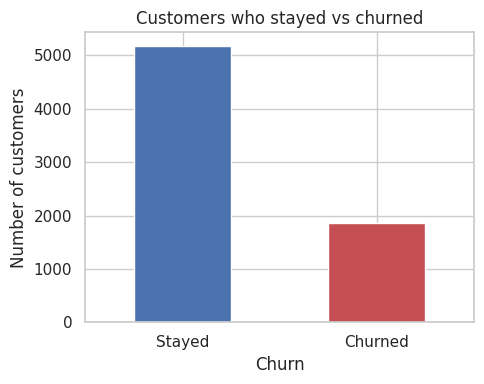

In [6]:
churn_rate = df["Churn"].mean()
print(f"Customers who churned: {df['Churn'].sum():,} of {len(df):,} ({churn_rate:.1%})")

fig, ax = plt.subplots(figsize=(5, 4))
df["Churn"].map({0: "Stayed", 1: "Churned"}).value_counts().plot(
    kind="bar", color=["#4C72B0", "#C44E52"], rot=0, ax=ax)
ax.set_title("Customers who stayed vs churned")
ax.set_ylabel("Number of customers")
plt.tight_layout()
plt.savefig("images/01_churn_balance.png", dpi=150)
plt.show()

**Finding:** 26.5% of customers churned. The classes are imbalanced: a model that always predicts "stayed" would reach
73.5% accuracy without identifying a single churner. Models are therefore evaluated with ROC-AUC, precision and
recall instead of accuracy.

### 3.2 Contract type

Contract
Month-to-month    42.7
One year          11.3
Two year           2.8
Name: Churn, dtype: float64

Month-to-month customers: 55.0% of all customers, 88.6% of all churners


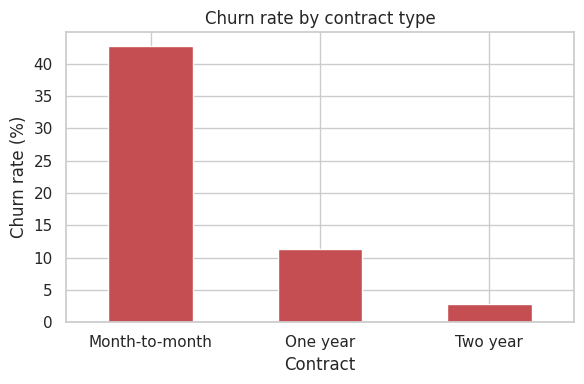

In [7]:
contract_churn = df.groupby("Contract")["Churn"].mean().sort_values(ascending=False)
print((contract_churn * 100).round(1))

mtm = df[df["Contract"] == "Month-to-month"]
print(f"\nMonth-to-month customers: {len(mtm) / len(df):.1%} of all customers, "
      f"{mtm['Churn'].sum() / df['Churn'].sum():.1%} of all churners")

fig, ax = plt.subplots(figsize=(6, 4))
contract_churn.mul(100).plot(kind="bar", color="#C44E52", rot=0, ax=ax)
ax.set_title("Churn rate by contract type")
ax.set_ylabel("Churn rate (%)")
plt.tight_layout()
plt.savefig("images/02_churn_by_contract.png", dpi=150)
plt.show()

**Finding:** Month-to-month customers churn at 42.7%, compared with 11.3% on one-year and 2.8% on two-year contracts.
They make up 55% of the customer base but 88.6% of all churners.

### 3.3 Tenure

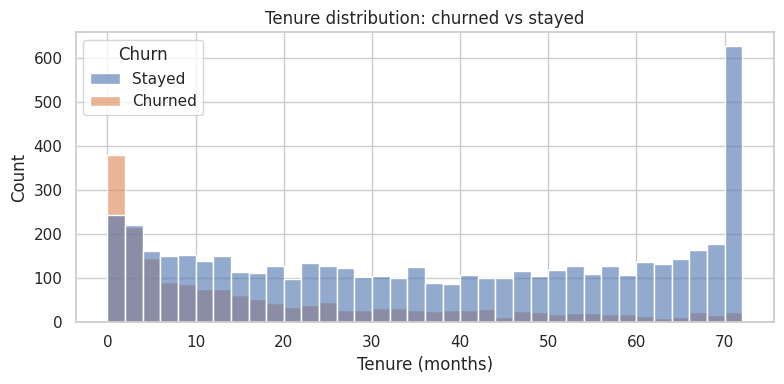

Churn rate (%) by tenure band (months):
             churn_rate  customers
tenure_band                       
0-5                54.3       1371
6-12               36.0        815
13-24              28.7       1024
25-48              20.4       1594
49-72               9.5       2239

Median tenure (months): {'Stayed': 38.0, 'Churned': 10.0}


In [8]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(data=df, x="tenure", hue=df["Churn"].map({0: "Stayed", 1: "Churned"}),
             bins=36, multiple="layer", alpha=0.6, ax=ax)
ax.set_title("Tenure distribution: churned vs stayed")
ax.set_xlabel("Tenure (months)")
plt.tight_layout()
plt.savefig("images/03_tenure_distribution.png", dpi=150)
plt.show()

df["tenure_band"] = pd.cut(df["tenure"], bins=[-1, 5, 12, 24, 48, 72],
                           labels=["0-5", "6-12", "13-24", "25-48", "49-72"])
band = df.groupby("tenure_band", observed=True)["Churn"].agg(churn_rate="mean", customers="size")
band["churn_rate"] = (band["churn_rate"] * 100).round(1)
print("Churn rate (%) by tenure band (months):")
print(band)
print("\nMedian tenure (months):", df.groupby("Churn")["tenure"].median().rename({0: "Stayed", 1: "Churned"}).to_dict())
df = df.drop(columns=["tenure_band"])

**Finding:** Churn is concentrated early in the customer lifecycle. 54.3% of customers in their first six months
churn, falling to 9.5% for customers beyond four years. Churned customers have a median tenure of 10 months,
against 38 months for those who stayed.

### 3.4 Monthly charges

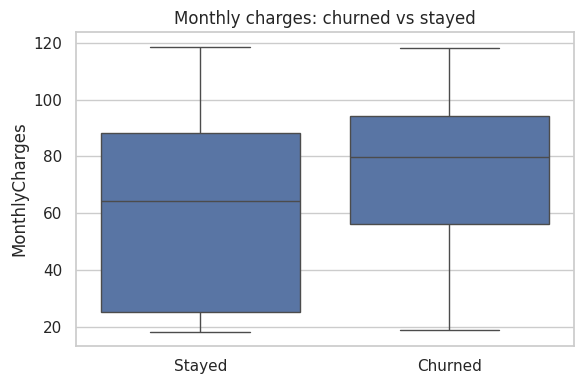

Median monthly charges: {'Stayed': 64.43, 'Churned': 79.65}


In [9]:
fig, ax = plt.subplots(figsize=(6, 4))
sns.boxplot(data=df, x=df["Churn"].map({0: "Stayed", 1: "Churned"}), y="MonthlyCharges", ax=ax)
ax.set_xlabel("")
ax.set_title("Monthly charges: churned vs stayed")
plt.tight_layout()
plt.savefig("images/04_monthly_charges.png", dpi=150)
plt.show()

print("Median monthly charges:", df.groupby("Churn")["MonthlyCharges"].median().rename({0: "Stayed", 1: "Churned"}).round(2).to_dict())

**Finding:** Churned customers pay more per month (median 79.65 against 64.43).

### 3.5 Internet service and payment method

InternetService
Fiber optic    41.9
DSL            19.0
No              7.4 

PaymentMethod
Electronic check             45.3
Mailed check                 19.1
Bank transfer (automatic)    16.7
Credit card (automatic)      15.2 



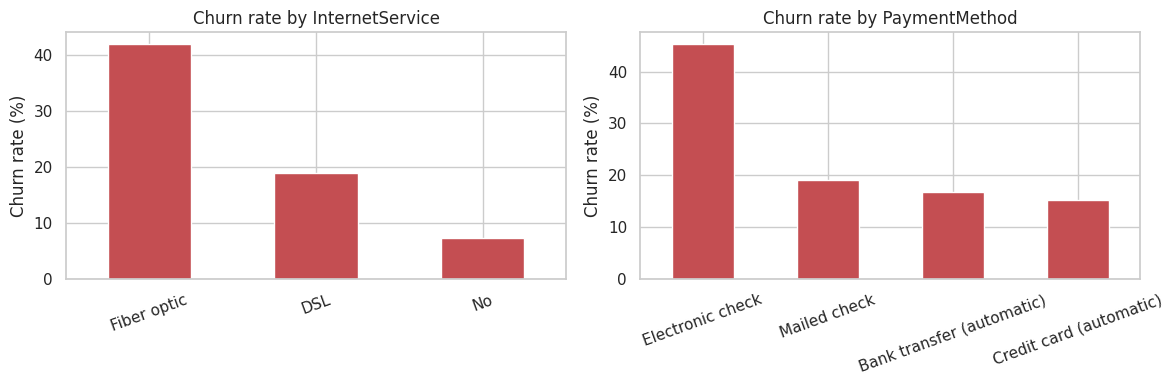

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, col in zip(axes, ["InternetService", "PaymentMethod"]):
    rate = df.groupby(col)["Churn"].mean().sort_values(ascending=False) * 100
    print((rate.round(1)).to_string(), "\n")
    rate.plot(kind="bar", color="#C44E52", ax=ax, rot=20)
    ax.set_title(f"Churn rate by {col}")
    ax.set_ylabel("Churn rate (%)")
    ax.set_xlabel("")
plt.tight_layout()
plt.savefig("images/05_churn_by_service_payment.png", dpi=150)
plt.show()

**Finding:** Fiber optic customers churn at 41.9%, against 19.0% for DSL and 7.4% for customers without internet service.
Customers paying by electronic check churn at 45.3%, while those on automatic payment methods or mailed checks
sit between 15% and 19%.

### 3.6 Summary of exploratory findings
1. Month-to-month contracts carry the highest churn (42.7%) and account for most churners.
2. Churn is highest in the first six months of tenure (54.3%).
3. Churned customers pay more per month than those who stay.
4. Fiber optic customers and electronic check payers show unusually high churn.

## 4. Modelling

### 4.1 Train/test split
20% of customers are held out as a test set. The split is stratified on the target so both parts keep the same churn rate.

In [11]:
X = df.drop(columns=["Churn"])
y = df["Churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED)

print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Churn rate train: {:.1%} | test: {:.1%}".format(y_train.mean(), y_test.mean()))

Train: (5634, 19) | Test: (1409, 19)
Churn rate train: 26.5% | test: 26.5%


### 4.2 Preprocessing
Numeric columns are standardised and categorical columns one-hot encoded. The transformer is part of each model pipeline,
so it is fitted on training data only.

In [12]:
numeric_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
categorical_cols = [c for c in X.columns if c not in numeric_cols]

preprocess = ColumnTransformer([
    ("num", StandardScaler(), numeric_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols),
])
print("Numeric columns:", numeric_cols)
print("Categorical columns:", len(categorical_cols))

Numeric columns: ['tenure', 'MonthlyCharges', 'TotalCharges']
Categorical columns: 16


### 4.3 Evaluation
Both models are scored the same way: ROC-AUC, precision, recall and F1 on the test set at a 0.5 threshold, plus a confusion matrix.

In [13]:
def evaluate(name, model, X_test, y_test):
    proba = model.predict_proba(X_test)[:, 1]
    pred = (proba >= 0.5).astype(int)
    results = {
        "Model": name,
        "ROC-AUC": roc_auc_score(y_test, proba),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
    }
    print(f"=== {name} ===")
    print(classification_report(y_test, pred, target_names=["Stayed", "Churned"]))
    ConfusionMatrixDisplay(confusion_matrix(y_test, pred),
                           display_labels=["Stayed", "Churned"]).plot(cmap="Blues", values_format="d")
    plt.title(f"Confusion matrix: {name}")
    plt.tight_layout()
    plt.savefig(f"images/cm_{name.replace(' ', '_').lower()}.png", dpi=150)
    plt.show()
    return results, proba

### 4.4 Model 1: Logistic regression (baseline)
Balanced class weights penalise missed churners more heavily, which offsets the class imbalance.

=== Logistic Regression ===
              precision    recall  f1-score   support

      Stayed       0.90      0.72      0.80      1035
     Churned       0.50      0.78      0.61       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409



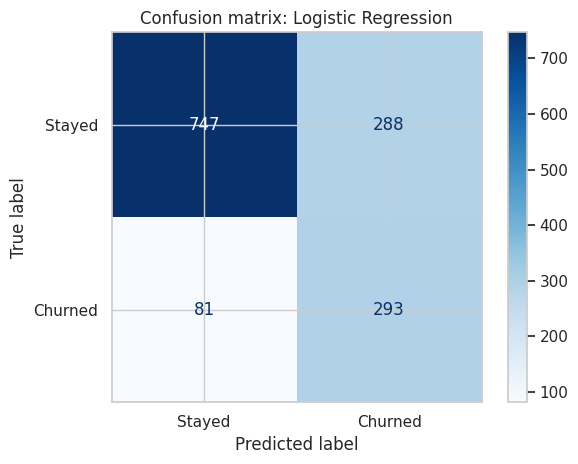

In [14]:
log_reg = Pipeline([
    ("prep", preprocess),
    ("model", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=SEED)),
])
log_reg.fit(X_train, y_train)
res_lr, proba_lr = evaluate("Logistic Regression", log_reg, X_test, y_test)

### 4.5 Model 2: Random forest
300 trees with a minimum leaf size of 5 to limit overfitting, and the same balanced class weights.

=== Random Forest ===
              precision    recall  f1-score   support

      Stayed       0.90      0.78      0.83      1035
     Churned       0.55      0.75      0.64       374

    accuracy                           0.77      1409
   macro avg       0.72      0.76      0.73      1409
weighted avg       0.80      0.77      0.78      1409



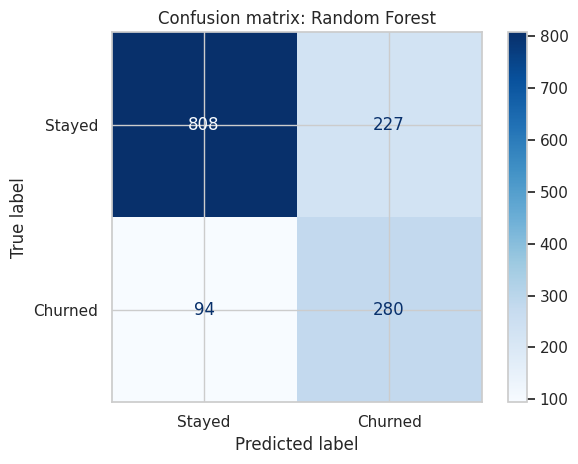

In [15]:
rf = Pipeline([
    ("prep", preprocess),
    ("model", RandomForestClassifier(n_estimators=300, min_samples_leaf=5,
                                     class_weight="balanced", random_state=SEED, n_jobs=-1)),
])
rf.fit(X_train, y_train)
res_rf, proba_rf = evaluate("Random Forest", rf, X_test, y_test)

### 4.6 Model comparison

,ROC-AUC,Precision,Recall,F1
Model,,,,
Logistic Regression,0.842,0.504,0.783,0.614
Random Forest,0.842,0.552,0.749,0.636


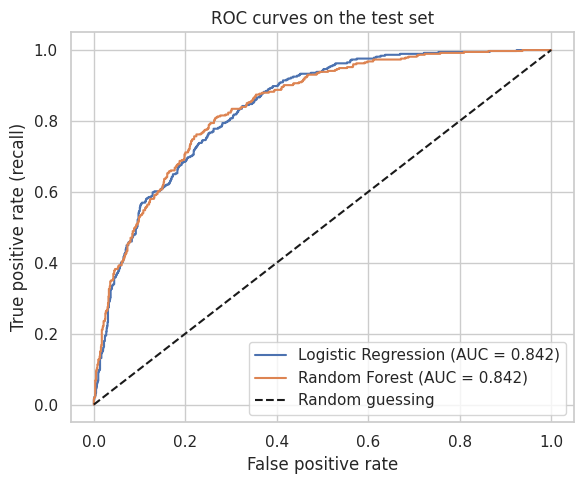

In [16]:
comparison = pd.DataFrame([res_lr, res_rf]).set_index("Model").round(3)
display(comparison)

fpr_lr, tpr_lr, _ = roc_curve(y_test, proba_lr)
fpr_rf, tpr_rf, _ = roc_curve(y_test, proba_rf)
plt.figure(figsize=(6, 5))
plt.plot(fpr_lr, tpr_lr, label=f"Logistic Regression (AUC = {res_lr['ROC-AUC']:.3f})")
plt.plot(fpr_rf, tpr_rf, label=f"Random Forest (AUC = {res_rf['ROC-AUC']:.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random guessing")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate (recall)")
plt.title("ROC curves on the test set")
plt.legend()
plt.tight_layout()
plt.savefig("images/06_roc_curves.png", dpi=150)
plt.show()

**Finding:** Both models reach a ROC-AUC of 0.842, and the ROC curves almost overlap. Logistic regression catches more
churners (recall 0.78 against 0.75) while the random forest raises fewer false alarms (precision 0.55 against 0.50).
The F1 scores are close (0.61 and 0.64).

### 4.7 Cross-validation
A single test split can favour one model by chance, so both models are also compared with 5-fold stratified cross-validation
on the full dataset. The preprocessing is refitted inside each fold.

In [17]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
cv_rows = []
for name, model in [("Logistic Regression", log_reg), ("Random Forest", rf)]:
    scores = cross_val_score(model, X, y, cv=cv, scoring="roc_auc")
    cv_rows.append({"Model": name, "Mean ROC-AUC": scores.mean(), "Std": scores.std(),
                    "Folds": scores.round(3).tolist()})
pd.DataFrame(cv_rows).set_index("Model").round(3)

,Mean ROC-AUC,Std,Folds
Model,,,
Logistic Regression,0.845,0.013,"[0.855, 0.846, 0.863, 0.825, 0.836]"
Random Forest,0.844,0.012,"[0.859, 0.841, 0.857, 0.826, 0.837]"


**Finding:** Mean ROC-AUC is 0.845 for logistic regression and 0.844 for the random forest, with a fold-to-fold spread of
about 0.013. The difference between the models is far smaller than the variation between folds, so there is no measurable
difference in ranking quality.

**Model choice:** logistic regression. It ranks customers as well as the random forest, trains instantly and exposes
interpretable coefficients. This conclusion applies to this dataset; a tuned model or different data could change it.

## 5. Drivers of churn

### 5.1 Logistic regression coefficients
Positive coefficients increase the predicted risk of churn; negative coefficients reduce it. Numeric features are standardised.

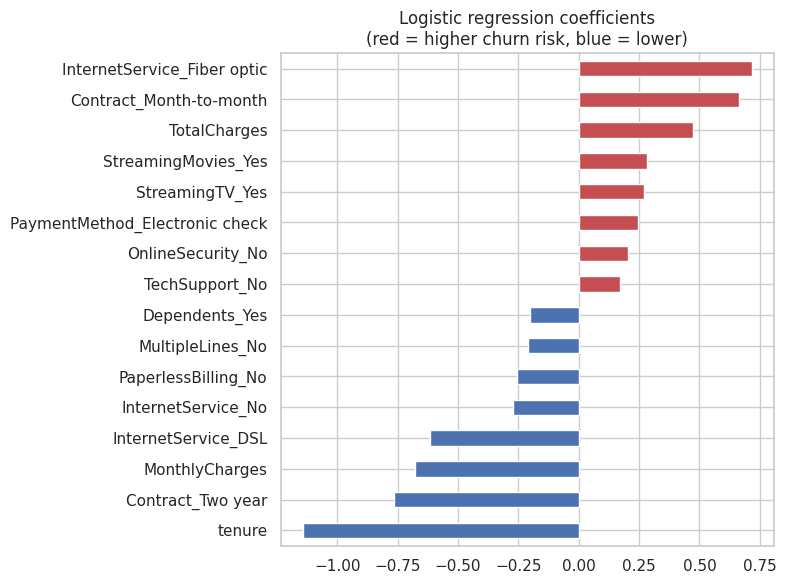

In [18]:
feature_names = log_reg.named_steps["prep"].get_feature_names_out()
coefs = pd.Series(log_reg.named_steps["model"].coef_[0], index=feature_names)
coefs = coefs.rename(lambda s: s.replace("num__", "").replace("cat__", ""))
coefs = coefs[~coefs.index.str.contains("No internet service")]   # duplicates of InternetService_No

top = pd.concat([coefs.sort_values().head(8), coefs.sort_values().tail(8)])
plt.figure(figsize=(8, 6))
top.plot(kind="barh", color=["#4C72B0" if v < 0 else "#C44E52" for v in top])
plt.title("Logistic regression coefficients\n(red = higher churn risk, blue = lower)")
plt.tight_layout()
plt.savefig("images/07_logreg_coefficients.png", dpi=150)
plt.show()

### 5.2 Random forest feature importance

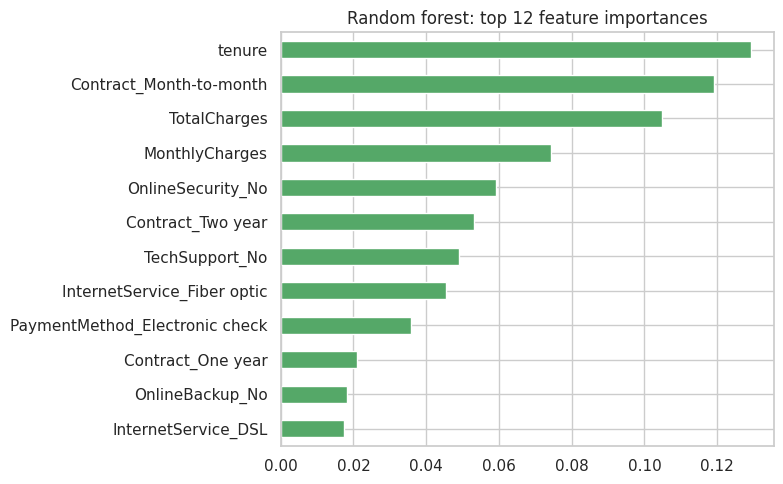

In [19]:
rf_names = rf.named_steps["prep"].get_feature_names_out()
imp = pd.Series(rf.named_steps["model"].feature_importances_, index=rf_names)
imp = imp.rename(lambda s: s.replace("num__", "").replace("cat__", "")).sort_values().tail(12)

plt.figure(figsize=(8, 5))
imp.plot(kind="barh", color="#55A868")
plt.title("Random forest: top 12 feature importances")
plt.tight_layout()
plt.savefig("images/08_rf_importance.png", dpi=150)
plt.show()

**Finding:** Both models point to the same drivers.
- **Higher churn risk:** fiber optic internet, month-to-month contracts, electronic check payment, streaming add-ons,
  and no online security or tech support.
- **Lower churn risk:** long tenure, two-year contracts and DSL internet.
- The random forest ranks tenure, contract type and total charges as its most important features.

The coefficients for `MonthlyCharges` and `TotalCharges` should be read with care. Both are strongly correlated with the
service add-ons in the dataset, so their signs are affected by multicollinearity. The exploratory analysis is the
better reference for pricing: churned customers pay more per month.

Both views describe association, not cause. A feature can predict churn without causing it.

## 6. Risk segmentation for retention

A retention team cannot contact every customer. Test customers are ranked by predicted churn probability
(logistic regression) and split into five equal groups. Lift compares each group's churn rate with the overall rate.

,customers,actual_churn_rate,churners,share_of_all_churners,lift
risk_group,,,,,
1 (lowest),282,0.011,3,0.008,0.040
2,282,0.074,21,0.056,0.281
3,281,0.210,59,0.158,0.791
4,282,0.372,105,0.281,1.403
5 (highest),282,0.660,186,0.497,2.485


The top 20% highest-risk customers contain 50% of all churners (2.5x lift).


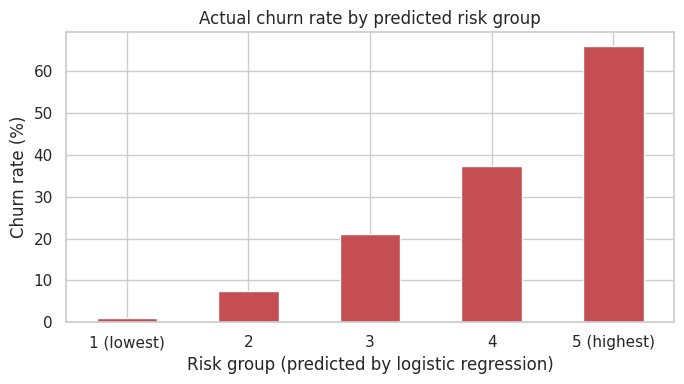

In [20]:
risk = pd.DataFrame({"churn_probability": proba_lr, "churned": y_test.values})
risk["risk_group"] = pd.qcut(risk["churn_probability"].rank(method="first"), 5,
                             labels=["1 (lowest)", "2", "3", "4", "5 (highest)"])

summary = risk.groupby("risk_group", observed=True).agg(
    customers=("churned", "size"),
    actual_churn_rate=("churned", "mean"),
    churners=("churned", "sum"),
)
summary["share_of_all_churners"] = summary["churners"] / summary["churners"].sum()
summary["lift"] = summary["actual_churn_rate"] / y_test.mean()
display(summary.round(3))

top_share = summary.loc["5 (highest)", "share_of_all_churners"]
top_lift = summary.loc["5 (highest)", "lift"]
print(f"The top 20% highest-risk customers contain {top_share:.0%} of all churners ({top_lift:.1f}x lift).")

fig, ax = plt.subplots(figsize=(7, 4))
summary["actual_churn_rate"].mul(100).plot(kind="bar", color="#C44E52", rot=0, ax=ax)
ax.set_title("Actual churn rate by predicted risk group")
ax.set_ylabel("Churn rate (%)")
ax.set_xlabel("Risk group (predicted by logistic regression)")
plt.tight_layout()
plt.savefig("images/09_risk_groups.png", dpi=150)
plt.show()

**Finding:** Actual churn rises steadily across the groups, from 1.1% in the lowest-risk group to 66.0% in the highest.
The top 20% of customers contain 50% of all churners, a 2.5x lift over random selection. Contacting only that group
reaches half of the churn problem with a fifth of the effort.

### Profile of the highest-risk group

In [21]:
test_df = X_test.copy()
test_df["risk_group"] = risk["risk_group"].values
high = test_df[test_df["risk_group"] == "5 (highest)"]

for col in ["Contract", "InternetService", "PaymentMethod"]:
    print(f"--- {col} (share of highest-risk group) ---")
    print((high[col].value_counts(normalize=True) * 100).round(1).to_string(), "\n")

print("Median tenure, highest-risk group:", high["tenure"].median(), "months")
print("Median tenure, all test customers:", test_df["tenure"].median(), "months")

--- Contract (share of highest-risk group) ---
Contract
Month-to-month    100.0 

--- InternetService (share of highest-risk group) ---
InternetService
Fiber optic    90.1
DSL             9.9 

--- PaymentMethod (share of highest-risk group) ---
PaymentMethod
Electronic check             74.8
Credit card (automatic)       9.2
Mailed check                  8.9
Bank transfer (automatic)     7.1 

Median tenure, highest-risk group: 6.0 months
Median tenure, all test customers: 28.0 months


**Finding:** The highest-risk group is made up entirely of month-to-month customers. 90% use fiber optic internet,
75% pay by electronic check, and their median tenure is 6 months against 28 months for all test customers.

## 7. Conclusions

### Findings
- 26.5% of customers churned. Month-to-month contracts (42.7%), the first six months of tenure (54.3%),
  fiber optic internet (41.9%) and electronic check payment (45.3%) show the highest churn.
- Logistic regression and random forest perform equally well (ROC-AUC 0.842 on the test set, 0.845 and 0.844 in
  cross-validation). Logistic regression is the preferred model because it is simpler and interpretable.
- The 20% of customers with the highest predicted risk contain 50% of all churners.

### Recommendations
1. **Target new month-to-month customers first.** This group has the highest churn and the highest predicted risk.
2. **Move month-to-month customers to longer contracts.** Offer a discount or an added feature; one-year and two-year
   contracts churn at 11.3% and 2.8%.
3. **Strengthen onboarding in the first six months,** when more than half of customers churn.
4. **Review the electronic check payment experience** and the fiber optic service, where churn is unusually high.
5. **Promote online security and tech support add-ons,** since customers without them churn more.

### Limitations
- The data is a single snapshot from a telecom company, so the exact patterns will differ for a software business.
- The model identifies associations, not causes. An A/B experiment is needed to show that a retention offer reduces churn.
- No hyperparameter tuning was done, and the decision threshold was fixed at 0.5.

### Next steps
- Tune both models with cross-validation and test gradient boosting.
- Choose the decision threshold from the cost of a missed churner against the cost of a retention offer.
- Run a controlled test of a retention offer on the highest-risk group and measure the effect.